In [1]:
from IPython import display
import ultralytics

In [2]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [3]:
import cv2
import matplotlib.pyplot as plt

In [4]:
display.clear_output()
ultralytics.checks()

Ultralytics 8.4.175  Python-3.12.14 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
Setup complete  (12 CPUs, 15.9 GB RAM, 166.9/476.3 GB disk)


In [5]:
# เรียก best.pt ตรงๆ (head 3 class)
model = ultralytics.YOLO("runs/segment/poly_stage1/weights/best.pt")

In [6]:
import glob

imgs = sorted(glob.glob("dataset/polytrain/val/images/*.jpg"))
img = imgs[0]
result = model.predict(img)


image 1/1 c:\dip_s2\ml_lab\projectyolo\dataset\polytrain\val\images\000000002006.jpg: 480x640 3 Persons, 1 Bus, 10.1ms
Speed: 40.6ms preprocess, 10.1ms inference, 16.3ms postprocess per image at shape (1, 3, 480, 640)


mask =  4


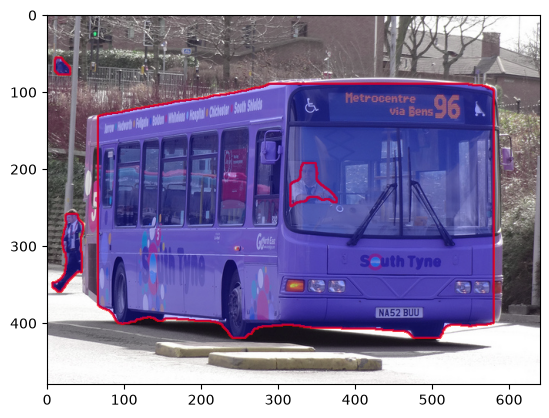

In [7]:
myimage = cv2.imread(img)
overlay = myimage.copy()
myimage = cv2.cvtColor(myimage, cv2.COLOR_BGR2RGB)

if result[0].masks is None:
    print("mask = 0")
else:
    print("mask = ", len(result[0].masks))
    for idx in range(len(result[0].masks)):
        x = result[0].masks.xy[idx].astype(int)
        pts = x.reshape((-1, 1, 2))
        myimage = cv2.polylines(myimage, [pts], isClosed=True, color=(255, 0, 0), thickness=2)
        overlay = cv2.fillPoly(overlay, pts=[pts], color=(0, 0, 255))
alpha = 0.25
myimage = cv2.addWeighted(overlay, alpha, myimage, 1 - alpha, 0)

plt.imshow(myimage)

In [8]:
# Predict ทุกรูปใน val -> เก็บภาพ + CSV ไว้ส่งอาจารย์
import csv
from collections import Counter

COLORS = {"Person": (0, 200, 0), "Car": (255, 140, 0), "Bus": (0, 0, 255)}  # RGB
OUT = "output/final/predict/poly"
os.makedirs(OUT, exist_ok=True)

rows = []
for path in imgs:
    result = model.predict(path, verbose=False)
    im = cv2.imread(path)
    overlay = im.copy()
    labels = []
    if result[0].masks is not None:
        for idx, box in enumerate(result[0].boxes):
            name = result[0].names[int(box.cls[0].item())]
            cf = round(box.conf[0].item(), 2)
            bgr = COLORS.get(name, (200, 200, 200))[::-1]
            pts = result[0].masks.xy[idx].astype(int).reshape((-1, 1, 2))
            im = cv2.polylines(im, [pts], isClosed=True, color=bgr, thickness=2)
            overlay = cv2.fillPoly(overlay, pts=[pts], color=bgr)
            x0, y0, x1, y1 = [round(v) for v in box.xyxy[0].tolist()]
            labels.append((name, cf, x0, y0, bgr))
            rows.append([os.path.basename(path), name, cf, x0, y0, x1, y1, len(pts)])
    im = cv2.addWeighted(overlay, 0.25, im, 0.75, 0)
    for name, cf, x0, y0, bgr in labels:
        im = cv2.putText(im, f"{name} {cf}", (x0, max(y0 - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, bgr, 2)
    cv2.imwrite(os.path.join(OUT, os.path.basename(path)), im)

with open("output/final/predict/predict_poly.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["image", "class", "conf", "x0", "y0", "x1", "y1", "n_points"])
    w.writerows(rows)
print(len(imgs), "images,", len(rows), "detections", dict(Counter(r[1] for r in rows)))

40 images, 180 detections {'Bus': 33, 'Person': 71, 'Car': 76}
